# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [ ]:
# Set up from midterm repo

# Setup: get the data and run the team's cleaning pipeline
import os
if not os.path.isdir('/content/ds2002-midterm'):
    !git clone -q https://github.com/ayanrasulova/ds2002-midterm.git

from pathlib import Path
import re

import pandas as pd

# find the project data folder, or in Colab
possible_data_dirs = [
    Path.cwd() / "data",
    Path.cwd().parent / "data",
    Path("/content/data"),
]
if Path("/content").is_dir():
    possible_data_dirs.extend(Path("/content").glob("**/data"))
DATA_DIR = next((path for path in possible_data_dirs if path.is_dir()), None)
if DATA_DIR is None:
    raise FileNotFoundError("could not find the data folder")
#read in data as plain text to avoid automatic conversion by Pandas
raw_transactions = pd.read_csv(
    DATA_DIR / "walmart_transactions.csv", dtype="string", keep_default_na=False
)
raw_stores = pd.read_csv(
    DATA_DIR / "store_locations.csv", dtype="string", keep_default_na=False
)
raw_products = pd.read_csv(
    DATA_DIR / "product_catalog.csv", dtype="string", keep_default_na=False
)

missing_tokens = {"", "NULL", "N/A", "NA", "NAN", "NONE"}
sku_groups = {
    "PT-12": ["PT-12", "SKU#459812", "POPTART-STRAW", "PT_STRAWBERRY"],
    "WTR-24": ["WTR-24", "WATER24PK", "WTR_24PK"],
    "BATT-100": ["BATT-100", "BAT-AA4", "BATT_AA_4PK"],
    "FLASH-01": ["FLASH-01", "LED-FLASH"],
    "BEER-24": ["BEER-24", "LTBEER24"],
    "BG-MONO": ["BG-MONO", "MONOPOLY-01", "GAME-MONO"],
    "CARDS-01": ["CARDS-01", "PLAYCARD-STD"],
    "STREAM-01": ["STREAM-01", "ROKU-STD"],
    "SOUP-CAN": ["SOUP-CAN", "CNSOUP-01"],
    "BREAD-WH": ["BREAD-WH", "WHITEBREAD"],
    "PB-16": ["PB-16", "PNUTBTR-16"],
    "CNDL-EM": ["CNDL-EM", "CANDLE-EMRG"],
    "FAID-01": ["FAID-01", "FIRSTAID-KIT"],
    "CHRG-PORT": ["CHRG-PORT", "PORTCHARGER"],
    "CHIPS-VP": ["CHIPS-VP", "CHIPVARIETY"],
    "PTOWEL-6": ["PTOWEL-6", "PAPERTOWEL6"],
    "TP-12": ["TP-12", "TOILETPAPER12"],
    "DIAP-S3": ["DIAP-S3", "DIAPERS-3"],
    "BFORM-01": ["BFORM-01", "BABYFORMULA"],
    "TARP-HD": ["TARP-HD", "HDTARP-01"],
}
# create a mapping of all known aliases to their canonical sku
sku_to_canonical = {
    alias.upper(): canonical
    for canonical, aliases in sku_groups.items()
    for alias in aliases
}
# standardize store ids and make empty strings and null-like values missing
def normalize_missing(frame):
    cleaned = frame.copy()
    for column in cleaned.select_dtypes(include=["object", "string"]).columns:
        values = cleaned[column].astype("string").str.strip()
        cleaned[column] = values.mask(values.str.upper().isin(missing_tokens), pd.NA)
    return cleaned

# standardize stores ids so they are all in 'FL' format to join
def normalize_store_id(values):
    text = values.astype("string").str.strip().str.upper()
    digits = text.str.extract(r"^FL[\s_-]?(\d{3})$", expand=False)
    return text.where(digits.isna(), "FL-" + digits)

# map spelling variations and capitalization to a canonical category name
def normalize_category(values):
    text = values.astype("string").str.strip().str.replace(r"\s+", " ", regex=True)
    key = text.str.casefold().str.replace(r"[^a-z0-9]", "", regex=True)
    category_names = {
        "breakfastfoods": "Breakfast", "breakfast": "Breakfast",
        "emergencysupplies": "Emergency", "emergency": "Emergency",
        "alcoholicbeverages": "Alcohol", "alcohol": "Alcohol",
        "groceries": "Grocery", "grocery": "Grocery",
        "householdessentials": "Household", "household": "Household",
        "babyproducts": "Baby", "baby": "Baby",
        "entertainment": "Entertainment", "electronics": "Electronics",
        "health": "Health", "snacks": "Snacks",
    }
    return key.map(category_names).fillna(text.str.title()).astype("string")

#convert numeric fields to numbers, removing currency symbols and commas
def to_number(values):
    text = values.astype("string").str.strip().str.replace(r"[$,~]", "", regex=True)
    return pd.to_numeric(text, errors="coerce")

def clean_transactions(transaction_data, store_data):
    before_rows = len(transaction_data)
    transactions = normalize_missing(transaction_data)
    missing_rows = int(transactions.isna().any(axis=1).sum())

    # keep the first copy of each transaction id
    transactions["transaction_id"] = transactions["transaction_id"].str.strip().str.upper()
    before_dedup = len(transactions)
    transactions = transactions.drop_duplicates(subset=["transaction_id"], keep="first").copy()
    duplicate_rows = before_dedup - len(transactions)

    # clean store values, drop duplicates
    stores = normalize_missing(store_data)
    old_store_ids = stores["store_id"].copy()
    stores["store_id"] = normalize_store_id(stores["store_id"])
    store_ids_changed = int(old_store_ids.ne(stores["store_id"]).fillna(False).sum())
    before_store_dedup = len(stores)
    stores = stores.drop_duplicates(subset=["store_id"], keep="first").copy()
    duplicate_stores = before_store_dedup - len(stores)

    # clean store ids to match the cleaned store file
    old_transaction_store_ids = transactions["store_id"].copy()
    transactions["store_id"] = normalize_store_id(transactions["store_id"])
    transaction_store_ids_changed = int(
        old_transaction_store_ids.ne(transactions["store_id"]).fillna(False).sum()
    )

    transactions["source_sku"] = transactions["sku"].astype("string").str.strip().str.upper()
    transactions["canonical_sku"] = transactions["source_sku"].map(sku_to_canonical).fillna(
        transactions["source_sku"]
    )
    sku_rows_changed = int(
        transactions["source_sku"].ne(transactions["canonical_sku"]).fillna(False).sum()
    )
    old_categories = transactions["category"].copy()
    transactions["category"] = normalize_category(transactions["category"])
    category_rows_changed = int(
        old_categories.ne(transactions["category"]).fillna(False).sum()
    )
    transactions["quantity"] = to_number(transactions["quantity"])
    transactions["unit_price"] = to_number(transactions["unit_price"])
    numeric_rows_touched = int(
        (transactions["quantity"].notna() | transactions["unit_price"].notna()).sum()
    )

    # parse mixed dates and convert local times to utc
    parsed = pd.to_datetime(transactions["timestamp"], format="mixed", errors="coerce")
    if parsed.dt.tz is None:
        parsed = parsed.dt.tz_localize(
            "America/New_York", ambiguous="NaT", nonexistent="NaT"
        )
    transactions["timestamp_local"] = parsed
    transactions["timestamp_utc"] = parsed.dt.tz_convert("UTC")

    # keep negative quantities aside for review
    negative_mask = transactions["quantity"].lt(0).fillna(False)
    quarantined = transactions.loc[negative_mask].copy()
    cleaned = transactions.loc[~negative_mask].copy()
    cleaned = cleaned.merge(
        stores[["store_id", "store_name", "city", "state", "region"]],
        on="store_id", how="left", validate="many_to_one",
    )

    decisions = pd.DataFrame([
        {"decision": "missing values", "action": "kept null-like fields as missing", "rows_touched": missing_rows},
        {"decision": "duplicate transactions", "action": "kept first transaction id", "rows_touched": duplicate_rows},
        {"decision": "store ids", "action": "standardized transaction ids", "rows_touched": transaction_store_ids_changed},
        {"decision": "store file", "action": "standardized ids and removed duplicate stores", "rows_touched": store_ids_changed + duplicate_stores},
        {"decision": "sku aliases", "action": "mapped source skus to canonical skus", "rows_touched": sku_rows_changed},
        {"decision": "categories", "action": "standardized names and capitalization", "rows_touched": category_rows_changed},
        {"decision": "numeric fields", "action": "converted quantity and price to numbers", "rows_touched": numeric_rows_touched},
        {"decision": "timestamps", "action": "parsed and converted valid times to utc", "rows_touched": int(parsed.notna().sum())},
        {"decision": "missing timestamps", "action": "left unparsed times as missing", "rows_touched": int(parsed.isna().sum())},
        {"decision": "negative quantities", "action": "moved rows to transactions_quarantined", "rows_touched": len(quarantined)},
    ])
    return cleaned, quarantined, stores, decisions, before_rows

# run the cleaning pipeline
transactions_clean, transactions_quarantined, stores, decision_log, rows_before = clean_transactions(
    raw_transactions, raw_stores
)
print("rows before cleaning:", rows_before)
print("duplicate transaction rows removed:", int(decision_log.loc[decision_log["decision"] == "duplicate transactions", "rows_touched"].iloc[0]))
print("negative quantity rows quarantined:", len(transactions_quarantined))
print("rows after cleaning:", len(transactions_clean))

rows before cleaning: 25562
duplicate transaction rows removed: 30
negative quantity rows quarantined: 130
rows after cleaning: 25402


**The Numbers**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

BASELINE_START = "2024-09-01"
SURGE_START = "2024-09-18"
SURGE_END = "2024-10-01"

sales = transactions_clean.dropna(subset=["timestamp_local"]).copy()
sales["date"] = sales["timestamp_local"].dt.date

daily_sales = sales.groupby("date")["quantity"].sum()


all_dates = pd.date_range(BASELINE_START, SURGE_END, inclusive="left", freq="D").date


daily_sales = daily_sales.reindex(all_dates, fill_value=0)


baseline = daily_sales[
    (daily_sales.index >= pd.Timestamp(BASELINE_START).date()) &
    (daily_sales.index < pd.Timestamp(SURGE_START).date())
]

surge = daily_sales[
    (daily_sales.index >= pd.Timestamp(SURGE_START).date()) &
    (daily_sales.index < pd.Timestamp(SURGE_END).date())
]


baseline_avg = baseline.mean()
surge_avg = surge.mean()
multiple = surge_avg / baseline_avg


print("Baseline window: Sep 1-18")
print(f"Baseline average: {baseline_avg:.2f} units/day")

print("Surge window: Sep 19-30")
print(f"Surge average: {surge_avg:.2f} units/day")

print(f"Surge multiple across all stores: {multiple:.2f}x")

Baseline window: Sep 1-18
Baseline average: 1153.47 units/day
Surge window: Sep 19-30
Surge average: 2176.00 units/day
Surge multiple across all stores: 1.89x


**The Chart**

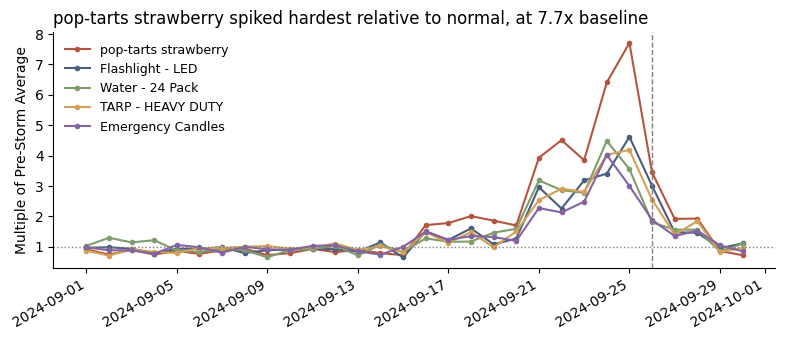

Ranked by surge multiple:
canonical_sku
pop-tarts strawberry    7.7
Flashlight - LED        4.6
Water - 24 Pack         4.5
TARP - HEAVY DUTY       4.2
Emergency Candles       4.0
dtype: Float64

--- Values for the Checkpoint Cell ---
top product: pop-tarts strawberry
surge multiple: 7.7
baseline window: Sep 1 to Sep 18


In [ ]:
import numpy as np, matplotlib.pyplot as plt

landfall_real = pd.Timestamp('2024-09-26')

sales = transactions_clean.dropna(subset=['timestamp_local']).copy()
sales['date'] = sales['timestamp_local'].dt.tz_localize(None).dt.normalize()
names = sales.dropna(subset=['product_name']).groupby('canonical_sku')['product_name'].first()

sales_daily = sales.pivot_table(index='date', columns='canonical_sku', values='quantity',
                                aggfunc='sum', fill_value=0)
sales_daily = sales_daily.reindex(pd.date_range(sales_daily.index.min(), sales_daily.index.max(), freq='D'),
                                  fill_value=0)

baseline_end = landfall_real - pd.Timedelta(days=7)
baseline_real = sales_daily[sales_daily.index < baseline_end].mean()
keep = baseline_real[baseline_real >= 1].index
indexed_real = sales_daily[keep] / baseline_real[keep]

surge = indexed_real.max().sort_values(ascending=False)
top5 = surge.index[:5]

fig, ax = plt.subplots(figsize=(8, 3.5))
for sku, color in zip(top5, ['#b4553f', '#4a5d7e', '#7f9c6c', '#d4a056', '#8464a0']):
    ax.plot(indexed_real.index, indexed_real[sku], marker='o', ms=3, color=color, label=names.get(sku, sku))
ax.axhline(1.0, ls=':', color='gray', lw=1)
ax.axvline(landfall_real, ls='--', color='gray', lw=1)
ax.set_title(f'{names.get(top5[0], top5[0])} spiked hardest relative to normal, at {surge.iloc[0]:.1f}x baseline',
             loc='left', fontsize=12)
ax.set_ylabel('Multiple of Pre-Storm Average')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

print('Ranked by surge multiple:')
print(surge.rename(index=names).round(1).head(5))


print('\n--- Values for the Checkpoint Cell ---')
print('top product:', names.get(top5[0], top5[0]))
print('surge multiple:', round(float(surge.iloc[0]), 1))
print('baseline window:', f'{sales_daily.index.min():%b %-d} to {baseline_end - pd.Timedelta(days=1):%b %-d}')

**Q1 answer, in one sentence a manager could read:** Our data shows that Strawberry Pop Tart sales spiked the most relative to normal, selling at a rate 770% of normal.

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

In [ ]:
products = raw_products.copy()
products["canonical_sku"] = products["sku"].astype("string").str.strip().str.upper().map(sku_to_canonical).fillna(products["sku"])

starting_skus = products["sku"].nunique()
ending_products = products["canonical_sku"].nunique()

family_summary = (
    products.groupby("canonical_sku")
    .agg(
        canonical_product=("product_name", "first"),
        original_sku_count=("sku", "nunique"),
        original_skus=("sku", lambda x: ", ".join(sorted(x)))
    )
    .sort_values("original_sku_count", ascending=False)
)

largest_family = family_summary.iloc[0]

print("Original distinct SKUs:", starting_skus)
print("Canonical products:", ending_products)
print("SKUs consolidated:", starting_skus - ending_products)
print("Largest consolidated family:", largest_family["canonical_product"])
print("Number of SKUs in largest family:", largest_family["original_sku_count"])
print("Unique SKUs:", largest_family["original_skus"])


before_units = transactions_clean["quantity"].sum()
after_units = transactions_clean.groupby("canonical_sku")["quantity"].sum().sum()

print(f"Units before consolidation: {before_units:,.0f}")
print(f"Units after consolidation:  {after_units:,.0f}")


assert before_units == after_units, ("Consolidation changed unit totals!")
print("Assertion passed: consolidation did not change unit totals.")

Original distinct SKUs: 45
Canonical products: 20
SKUs consolidated: 25
Largest consolidated family: pop-tarts strawberry
Number of SKUs in largest family: 4
Unique SKUs: POPTART-STRAW, PT-12, PT_STRAWBERRY, SKU#459812
Units before consolidation: 49,584
Units after consolidation:  49,584
Assertion passed: consolidation did not change unit totals.


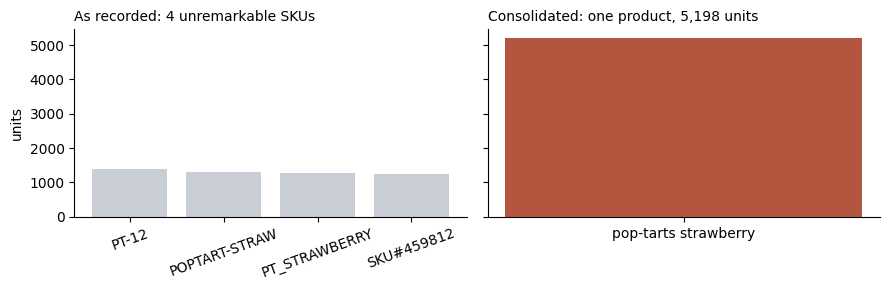

the consolidated total is 3.8x the largest single SKU
Total Pop-Tarts units: 5198


In [ ]:
family = 'PT-12'
pt = transactions_clean[transactions_clean['canonical_sku'] == family]
fragmented = pt.groupby('source_sku')['quantity'].sum().sort_values(ascending=False)
consolidated = pd.Series({names.get(family, family): fragmented.sum()})
multiple = fragmented.sum() / fragmented.max()

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
axes[0].bar(fragmented.index, fragmented.values, color='#c9cdd6')
axes[0].set_title(f'As recorded: {len(fragmented)} unremarkable SKUs', fontsize=10, loc='left')
axes[0].tick_params(axis='x', labelrotation=20)
axes[1].bar(consolidated.index, consolidated.values, color='#b4553f')
axes[1].set_title(f'Consolidated: one product, {int(fragmented.sum()):,} units', fontsize=10, loc='left')
axes[0].set_ylabel('units')
for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()


print(f'the consolidated total is {multiple:.1f}x the largest single SKU')
print("Total Pop-Tarts units:", fragmented.sum())

**Q2 answer:** The true average daily sales volume of poptarts is around 167 units per day, with total pop tart sales hitting 5,198. If we had not consolidatd the SKUs, it would be difficult to grasp the true volume of pop tarts sold. If a business owner saw the fragmented view, they may underestimate the quantity of pop tarts sold, thus underestimating teh need for them when planning future inventory. The consolidated view reveals total demand and provides a more useful basis for inventory decisions and product reviews for the future.

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

In [ ]:
import time
import requests
import pandas as pd

# open-meteo historical weather api
WEATHER_BASE_URL = "https://archive-api.open-meteo.com/v1/archive"
WEATHER_VARIABLES = ["precipitation", "wind_speed_10m", "pressure_msl"]
RETRY_STATUSES = {429, 500, 502, 503, 504}

# one extra day so sept 30 eastern is fully covered in utc
WEATHER_START = "2024-09-01"
WEATHER_END = "2024-10-01"

# empty weather table if the api can't be reached
def empty_hourly_weather():
    weather = pd.DataFrame(columns=["store_id"] + WEATHER_VARIABLES + ["time_utc", "source"])
    weather[WEATHER_VARIABLES] = weather[WEATHER_VARIABLES].astype("float64")
    weather["time_utc"] = pd.to_datetime(weather["time_utc"], utc=True)
    return weather

# one api call for all stores (comma separated lat/lon)
def fetch_hourly_weather(coordinates, start, end, tries=3):
    params = {
        "latitude": ",".join(coordinates["latitude"].astype(str)),
        "longitude": ",".join(coordinates["longitude"].astype(str)),
        "start_date": start,
        "end_date": end,
        "hourly": ",".join(WEATHER_VARIABLES),
        "timezone": "GMT",  # utc, converted to eastern in the next cell
    }
    for attempt in range(1, tries + 1):
        try:
            response = requests.get(WEATHER_BASE_URL, params=params, timeout=30)
        except (requests.ConnectionError, requests.Timeout):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if response.status_code in RETRY_STATUSES and attempt < tries:
            time.sleep(2 ** attempt)
            continue
        response.raise_for_status()
        break

    locations = response.json()
    if isinstance(locations, dict):  # a single store comes back as one object, not a list
        locations = [locations]
    assert len(locations) == len(coordinates), "api returned a different number of locations"

    frames = []
    for store_id, latitude, location in zip(coordinates["store_id"], coordinates["latitude"], locations):
        # api snaps to its grid, so check each result is near its store
        assert abs(location["latitude"] - latitude) < 0.5, f"location order mismatch at {store_id}"
        assert location["utc_offset_seconds"] == 0, "expected utc times from the api"
        frame = pd.DataFrame(location["hourly"])
        frame.insert(0, "store_id", store_id)
        frames.append(frame)
    hourly = pd.concat(frames, ignore_index=True)
    hourly["store_id"] = hourly["store_id"].astype("string")
    hourly = hourly.rename(columns={"time": "time_utc"})
    hourly["time_utc"] = pd.to_datetime(hourly["time_utc"]).dt.tz_localize("UTC")
    hourly["source"] = "open-meteo"
    return hourly

# tallahassee (FL-619) has no coordinates, use the city center
store_coordinates = stores[["store_id", "city", "latitude", "longitude"]].copy()
store_coordinates["latitude"] = pd.to_numeric(store_coordinates["latitude"], errors="coerce")
store_coordinates["longitude"] = pd.to_numeric(store_coordinates["longitude"], errors="coerce")
needs_fill = store_coordinates["store_id"].eq("FL-619") & store_coordinates["latitude"].isna()
store_coordinates.loc[needs_fill, ["latitude", "longitude"]] = [30.4383, -84.2807]
filled_coordinate_stores = store_coordinates.loc[needs_fill, "store_id"].tolist()
no_coordinates = store_coordinates[["latitude", "longitude"]].isna().any(axis=1)
store_coordinates = store_coordinates.loc[~no_coordinates].reset_index(drop=True)
print(f"filled coordinates for: {filled_coordinate_stores}")
print(f"stores still missing coordinates, skipped: {int(no_coordinates.sum())}")

if store_coordinates.empty:
    print("Warning: no store coordinates loaded, skipping the weather api call.")
    weather_hourly = empty_hourly_weather()
else:
    try:
        weather_hourly = fetch_hourly_weather(store_coordinates, WEATHER_START, WEATHER_END)
    except Exception as error:
        print(f"Warning: weather api call failed ({error}). Leaving weather empty.")
        weather_hourly = empty_hourly_weather()

print(f"weather source: {WEATHER_BASE_URL}")
print(f"stores requested: {len(store_coordinates)}, hourly rows returned: {len(weather_hourly):,}")
display(weather_hourly.head())

filled coordinates for: ['FL-619']
stores still missing coordinates, skipped: 0
weather source: https://archive-api.open-meteo.com/v1/archive
stores requested: 12, hourly rows returned: 8,928


,store_id,time_utc,precipitation,wind_speed_10m,pressure_msl,source
0,FL-239,2024-09-01 00:00:00+00:00,0.0,7.2,1014.1,open-meteo
1,FL-239,2024-09-01 01:00:00+00:00,0.0,6.8,1014.5,open-meteo
2,FL-239,2024-09-01 02:00:00+00:00,0.0,10.3,1015.1,open-meteo
3,FL-239,2024-09-01 03:00:00+00:00,0.0,8.9,1015.1,open-meteo
4,FL-239,2024-09-01 04:00:00+00:00,0.0,7.9,1015.2,open-meteo


In [ ]:
SALES_START = pd.Timestamp("2024-09-01")
SALES_END = pd.Timestamp("2024-09-30")

# hourly utc weather -> one row per store and eastern day
def daily_weather(hourly):
    assert hourly[WEATHER_VARIABLES].notna().all().all(), "api returned null hourly values"
    hourly = hourly.sort_values(["store_id", "time_utc"]).reset_index(drop=True)
    hourly["date"] = hourly["time_utc"].dt.tz_convert("America/New_York").dt.tz_localize(None).dt.normalize()
    # open-meteo stamps rain at the end of the hour, so take each hour's rain from the next row
    hourly["rain_in_hour"] = hourly.groupby("store_id")["precipitation"].shift(-1)
    daily = hourly.groupby(["store_id", "date"], as_index=False).agg(
        precipitation_mm=("rain_in_hour", "sum"),
        max_wind_kmh=("wind_speed_10m", "max"),
        min_pressure_hpa=("pressure_msl", "min"),
        hours=("time_utc", "size"),
        rain_hours=("rain_in_hour", "count"),
        source=("source", "first"),
    )
    # drop the partial days from the extra padding
    daily = daily[daily["date"].between(SALES_START, SALES_END)].reset_index(drop=True)
    assert not daily.duplicated(["store_id", "date"]).any(), "more than one weather row per store and day"
    assert daily["hours"].eq(24).all() and daily["rain_hours"].eq(24).all(), "some store-days are missing hours"
    return daily

# show the conversion, the first 4 utc hours of each day are still the day before in eastern time
weather_hourly["time_local"] = weather_hourly["time_utc"].dt.tz_convert("America/New_York")
shifted_weather_hours = int((weather_hourly["time_local"].dt.date != weather_hourly["time_utc"].dt.date).sum())
print(f"hourly weather rows that fall on a different day in eastern time: {shifted_weather_hours:,}")
display(weather_hourly[["store_id", "time_utc", "time_local"]].head())

weather_daily = daily_weather(weather_hourly)
trimmed_weather_hours = len(weather_hourly) - int(weather_daily["hours"].sum())
print(f"padded hours trimmed: {trimmed_weather_hours:,}")
print(f"weather_daily: {len(weather_daily):,} rows "
      f"({weather_daily['store_id'].nunique()} stores x {weather_daily['date'].nunique()} days)")
display(weather_daily.head())

hourly weather rows that fall on a different day in eastern time: 1,488


,store_id,time_utc,time_local
0,FL-239,2024-09-01 00:00:00+00:00,2024-08-31 20:00:00-04:00
1,FL-239,2024-09-01 01:00:00+00:00,2024-08-31 21:00:00-04:00
2,FL-239,2024-09-01 02:00:00+00:00,2024-08-31 22:00:00-04:00
3,FL-239,2024-09-01 03:00:00+00:00,2024-08-31 23:00:00-04:00
4,FL-239,2024-09-01 04:00:00+00:00,2024-09-01 00:00:00-04:00


padded hours trimmed: 288
weather_daily: 360 rows (12 stores x 30 days)


,store_id,date,precipitation_mm,max_wind_kmh,min_pressure_hpa,hours,rain_hours,source
0,FL-078,2024-09-01,1.5,11.3,1011.9,24,24,open-meteo
1,FL-078,2024-09-02,2.9,8.3,1011.9,24,24,open-meteo
2,FL-078,2024-09-03,8.0,16.3,1013.9,24,24,open-meteo
3,FL-078,2024-09-04,15.6,15.3,1016.8,24,24,open-meteo
4,FL-078,2024-09-05,13.3,13.8,1015.4,24,24,open-meteo


In [ ]:
# date sales by eastern time (utc would push evening sales to the next day)
sales_for_weather = transactions_clean.dropna(subset=["timestamp_local"]).copy()
no_timestamp_rows = len(transactions_clean) - len(sales_for_weather)
sales_for_weather["date"] = sales_for_weather["timestamp_local"].dt.tz_localize(None).dt.normalize()
utc_date = sales_for_weather["timestamp_utc"].dt.tz_localize(None).dt.normalize()
utc_shifted_rows = int((utc_date != sales_for_weather["date"]).sum())
print(f"transactions with no timestamp, left out of daily tables: {no_timestamp_rows:,}")
print(f"transactions that would move to the next day if dated by utc: {utc_shifted_rows:,} "
      f"({utc_shifted_rows / max(len(sales_for_weather), 1):.1%})")

# category labels the product catalog doesn't use
extra_categories = sorted(set(sales_for_weather["category"].dropna()) - set(products["category"].dropna()))
print(f"categories not in the product catalog: {extra_categories}")

daily_store_sales = sales_for_weather.groupby(["store_id", "date"], as_index=False).agg(
    units=("quantity", "sum"),
    transactions=("transaction_id", "size"),
)
# same thing split by category
daily_category_sales = sales_for_weather.groupby(["store_id", "date", "category"], as_index=False).agg(
    units=("quantity", "sum"),
    transactions=("transaction_id", "size"),
)
assert daily_store_sales["units"].sum() == sales_for_weather["quantity"].sum(), "store-day rollup lost units"
assert daily_category_sales["units"].sum() == sales_for_weather["quantity"].sum(), "category rollup lost units"
print(f"daily_store_sales: {len(daily_store_sales):,} rows, daily_category_sales: {len(daily_category_sales):,} rows")
display(daily_store_sales.head())

transactions with no timestamp, left out of daily tables: 881
transactions that would move to the next day if dated by utc: 4,381 (17.9%)
categories not in the product catalog: ['Alcohol', 'Entertainment', 'Games & Entertainment', 'Health', 'Health & Wellness']
daily_store_sales: 360 rows, daily_category_sales: 4,045 rows


,store_id,date,units,transactions
0,FL-078,2024-09-01,77,42
1,FL-078,2024-09-02,103,49
2,FL-078,2024-09-03,101,47
3,FL-078,2024-09-04,84,46
4,FL-078,2024-09-05,90,43


In [ ]:
# left join weather onto sales and check nothing changed
def join_weather(sales_frame, name):
    joined = sales_frame.merge(
        weather_daily, on=["store_id", "date"], how="left",
        validate="many_to_one", indicator=True,
    )
    print(f"{name}: {joined['_merge'].value_counts().to_dict()}")
    assert len(joined) == len(sales_frame), f"{name}: join changed the row count"
    assert not joined["_merge"].eq("right_only").any(), f"{name}: right_only rows present"
    assert joined["units"].sum() == sales_frame["units"].sum(), f"{name}: join changed total units"
    print(f"{name}: {len(sales_frame):,} rows before, {len(joined):,} after, units unchanged")
    joined["has_weather"] = joined["_merge"].eq("both")
    return joined.drop(columns="_merge")

store_day_weather = join_weather(daily_store_sales, "store-day sales")
category_day_weather = join_weather(daily_category_sales, "store-day-category sales")

# sales days with no weather
unmatched_sales_days = store_day_weather.loc[~store_day_weather["has_weather"], ["store_id", "date"]]
print(f"store-days with no weather: {len(unmatched_sales_days)}")
if len(unmatched_sales_days) > 0:
    display(unmatched_sales_days)

# weather days with no sales
weather_without_sales = len(weather_daily) - int(store_day_weather["has_weather"].sum())
print(f"store-days with weather but no sales: {weather_without_sales}")
display(store_day_weather.head())

store-day sales: {'both': 360, 'left_only': 0, 'right_only': 0}
store-day sales: 360 rows before, 360 after, units unchanged
store-day-category sales: {'both': 4045, 'left_only': 0, 'right_only': 0}
store-day-category sales: 4,045 rows before, 4,045 after, units unchanged
store-days with no weather: 0
store-days with weather but no sales: 0


,store_id,date,units,transactions,precipitation_mm,max_wind_kmh,min_pressure_hpa,hours,rain_hours,source,has_weather
0,FL-078,2024-09-01,77,42,1.5,11.3,1011.9,24,24,open-meteo,True
1,FL-078,2024-09-02,103,49,2.9,8.3,1011.9,24,24,open-meteo,True
2,FL-078,2024-09-03,101,47,8.0,16.3,1013.9,24,24,open-meteo,True
3,FL-078,2024-09-04,84,46,15.6,15.3,1016.8,24,24,open-meteo,True
4,FL-078,2024-09-05,90,43,13.3,13.8,1015.4,24,24,open-meteo,True


In [ ]:
# weather decisions and how many rows each one touched
weather_decision_log = pd.DataFrame([
    ("weather source", f"open-meteo historical api, {WEATHER_BASE_URL}, free with no key",
     len(weather_hourly)),
    ("missing store coordinates", f"filled {filled_coordinate_stores} (tallahassee) with the city center",
     len(filled_coordinate_stores)),
    ("weather timezone", "pulled hourly in utc, converted to America/New_York before rolling up to days",
     shifted_weather_hours),
    ("padded weather range", "requested sept 1 - oct 1 utc so every eastern sept day has 24 hours, partial edge days trimmed",
     trimmed_weather_hours),
    ("daily weather values", "rain summed by the eastern hour it fell in, wind speed max, pressure min per store and day",
     len(weather_daily)),
    ("sales date", "dated by timestamp_local (eastern), not timestamp_utc",
     utc_shifted_rows),
    ("missing timestamps", "transactions with no timestamp left out of the daily tables, can't be put on a day",
     no_timestamp_rows),
    ("pensacola timezone", "FL-710 is on central time, treated as eastern like the rest of the sales (brief says EST)",
     int(sales_for_weather["store_id"].eq("FL-710").sum())),
    ("unmatched days", "left join keeps every sales day, missing weather stays NaN, never filled with sample data",
     len(unmatched_sales_days)),
], columns=["decision", "what_it_did", "rows_touched"])
display(weather_decision_log)

,decision,what_it_did,rows_touched
0,weather source,"open-meteo historical api, https://archive-api...",8928
1,missing store coordinates,filled ['FL-619'] (tallahassee) with the city ...,1
2,weather timezone,"pulled hourly in utc, converted to America/New...",1488
3,padded weather range,requested sept 1 - oct 1 utc so every eastern ...,288
4,daily weather values,"rain summed by the eastern hour it fell in, wi...",360
5,sales date,"dated by timestamp_local (eastern), not timest...",4381
6,missing timestamps,transactions with no timestamp left out of the...,881
7,pensacola timezone,"FL-710 is on central time, treated as eastern ...",2066
8,unmatched days,"left join keeps every sales day, missing weath...",0


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

WEATHER_COLUMNS = ["precipitation_mm", "max_wind_kmh", "min_pressure_hpa"]
WEATHER_LABELS = {"precipitation_mm": "rain (mm)", "max_wind_kmh": "max wind (km/h)", "min_pressure_hpa": "min pressure (hPa)"}
LANDFALL = pd.Timestamp("2024-09-26")

# q3 only uses real api rows, no gaps
assert store_day_weather["has_weather"].all(), "some store-days have no weather"
assert store_day_weather["source"].eq("open-meteo").all(), "weather is not all live api data"

# statewide day: sum units over stores, average weather over store sites
statewide = store_day_weather.groupby("date").agg(
    units=("units", "sum"),
    **{column: (column, "mean") for column in WEATHER_COLUMNS},
)
statewide["units"] = statewide["units"].astype("float64")
assert len(statewide) == 30 and statewide.notna().all().all()

# normalize_category leaves these two as their own labels, fold them in here so q3 has 10 categories
CATEGORY_FIXES = {"Games & Entertainment": "Entertainment", "Health & Wellness": "Health"}
category_daily = (
    category_day_weather.assign(category=category_day_weather["category"].replace(CATEGORY_FIXES))
    .groupby(["date", "category"])["units"].sum().unstack().astype("float64")
)
assert category_daily.shape == (30, 10), category_daily.shape
assert category_daily.sum().sum() == statewide["units"].sum(), "category split lost units"

print(f"statewide days: {len(statewide)}, categories: {category_daily.shape[1]}, weather source: open-meteo (live)")
display(statewide.round(1))

statewide days: 30, categories: 10, weather source: open-meteo (live)


,units,precipitation_mm,max_wind_kmh,min_pressure_hpa
date,,,,
2024-09-01,1060.0,8.3,16.2,1012.4
2024-09-02,1168.0,7.5,14.0,1012.5
2024-09-03,1162.0,13.6,17.3,1013.9
2024-09-04,1115.0,14.5,17.5,1016.3
2024-09-05,1076.0,11.4,16.6,1014.9
2024-09-06,1104.0,11.4,15.4,1012.3
2024-09-07,1086.0,5.5,12.9,1010.4
2024-09-08,1097.0,17.3,14.8,1012.1
2024-09-09,1084.0,12.6,15.4,1014.3


In [ ]:
# same day: units vs that day's weather
same_day = pd.DataFrame({
    "pearson_r": [statewide["units"].corr(statewide[c]) for c in WEATHER_COLUMNS],
    "spearman_r": [statewide["units"].corr(statewide[c], method="spearman") for c in WEATHER_COLUMNS],
    "n_days": len(statewide),
}, index=[WEATHER_LABELS[c] for c in WEATHER_COLUMNS]).round(2)
display(same_day)

,pearson_r,spearman_r,n_days
rain (mm),-0.30,-0.23,30
max wind (km/h),0.23,0.34,30
min pressure (hPa),-0.24,-0.40,30


In [ ]:
# lagged: units on day t vs weather on day t + k
LAGS = range(-3, 6)

def lagged_corr(series, weather, k, method="pearson"):
    shifted = weather.shift(-k)
    keep = shifted.notna()
    return series[keep].corr(shifted[keep], method=method), int(keep.sum())

lag_rows = []
for k in LAGS:
    row = {"lag_days": k}
    for column in WEATHER_COLUMNS:
        row[WEATHER_LABELS[column]], row["n_days"] = lagged_corr(statewide["units"], statewide[column], k)
        row[WEATHER_LABELS[column] + " (spearman)"] = lagged_corr(statewide["units"], statewide[column], k, "spearman")[0]
    lag_rows.append(row)
lag_table = pd.DataFrame(lag_rows).set_index("lag_days").round(2)
display(lag_table)

best_lag = int(lag_table[WEATHER_LABELS["max_wind_kmh"]].idxmax())
print(f"strongest wind correlation at lag {best_lag:+d} days: "
      f"r = {lag_table.loc[best_lag, WEATHER_LABELS['max_wind_kmh']]:+.2f}, "
      f"pressure r = {lag_table.loc[best_lag, WEATHER_LABELS['min_pressure_hpa']]:+.2f}, "
      f"n = {lag_table.loc[best_lag, 'n_days']} days")

# same check per store-day (stores share one storm, so these are not independent)
by_store = store_day_weather.sort_values(["store_id", "date"]).copy()
by_store["units"] = by_store["units"].astype("float64")
shifted = by_store.groupby("store_id")[WEATHER_COLUMNS].shift(-best_lag)
keep = shifted.notna().all(axis=1)
print(f"store-day level at lag {best_lag:+d}: " + ", ".join(
    f"{WEATHER_LABELS[c]} r = {by_store.loc[keep, 'units'].corr(shifted.loc[keep, c]):+.2f}" for c in WEATHER_COLUMNS
) + f", n = {int(keep.sum())} store-days")

,rain (mm),n_days,rain (mm) (spearman),max wind (km/h),max wind (km/h) (spearman),min pressure (hPa),min pressure (hPa) (spearman)
lag_days,,,,,,,
-3,-0.62,27,-0.57,-0.24,-0.47,0.03,-0.21
-2,-0.61,28,-0.50,-0.11,-0.16,-0.06,-0.23
-1,-0.58,29,-0.59,0.04,-0.04,-0.13,-0.27
0,-0.30,30,-0.23,0.23,0.34,-0.24,-0.40
1,0.01,29,-0.27,0.58,0.24,-0.59,-0.46
2,0.02,28,-0.33,0.80,0.25,-0.80,-0.38
3,-0.06,27,-0.43,0.61,0.24,-0.62,-0.48
4,-0.03,26,-0.35,0.42,0.30,-0.43,-0.42
5,-0.10,25,-0.30,0.34,0.19,-0.36,-0.19


strongest wind correlation at lag +2 days: r = +0.80, pressure r = -0.80, n = 28 days
store-day level at lag +2: rain (mm) r = +0.01, max wind (km/h) r = +0.69, min pressure (hPa) r = -0.72, n = 336 store-days


In [ ]:
# per store: days from the sales peak to that store's own windiest day and lowest pressure
peak_rows = []
for store_id, group in store_day_weather.groupby("store_id"):
    group = group.set_index("date")
    sales_peak = group["units"].idxmax()
    wind_peak = group["max_wind_kmh"].idxmax()
    pressure_low = group["min_pressure_hpa"].idxmin()
    peak_rows.append({
        "store_id": store_id,
        "sales_peak": sales_peak.date(),
        "windiest_day": wind_peak.date(),
        "lowest_pressure_day": pressure_low.date(),
        "days_before_wind_peak": (wind_peak - sales_peak).days,
        "days_before_pressure_low": (pressure_low - sales_peak).days,
        "max_wind_kmh": group["max_wind_kmh"].max(),
        "min_pressure_hpa": group["min_pressure_hpa"].min(),
    })
store_peaks = (pd.DataFrame(peak_rows)
               .merge(stores[["store_id", "city"]], on="store_id", how="left", validate="one_to_one")
               .set_index("store_id"))
display(store_peaks)

lead_p = store_peaks["days_before_pressure_low"]
lead_w = store_peaks["days_before_wind_peak"]
print(f"sales peaked before the lowest pressure at {int(lead_p.gt(0).sum())} of {len(lead_p)} stores, "
      f"by {lead_p.min()}-{lead_p.max()} days (median {lead_p.median():.0f})")
print(f"sales peaked 1-3 days before the windiest day at {int(lead_w.between(1, 3).sum())} of {len(lead_w)} stores")
odd = store_peaks.loc[~lead_w.between(1, 3)]
if len(odd) > 0:
    print("windiest day outside the helene window:", odd[["city", "windiest_day", "max_wind_kmh"]].to_dict("index"))

,sales_peak,windiest_day,lowest_pressure_day,days_before_wind_peak,days_before_pressure_low,max_wind_kmh,min_pressure_hpa,city
store_id,,,,,,,,
FL-078,2024-09-25,2024-09-27,2024-09-26,2,1,52.9,990.3,Gainesville
FL-105,2024-09-25,2024-09-26,2024-09-26,1,1,70.1,993.5,Tampa
FL-156,2024-09-24,2024-09-26,2024-09-26,2,2,46.2,998.5,Daytona Beach
FL-239,2024-09-24,2024-09-26,2024-09-26,2,2,47.7,998.3,Orlando
FL-287,2024-09-25,2024-09-26,2024-09-26,1,1,46.4,998.8,Kissimmee
FL-302,2024-09-25,2024-09-26,2024-09-26,1,1,46.7,997.0,Lakeland
FL-330,2024-09-24,2024-09-26,2024-09-26,2,2,47.7,1005.6,Miami
FL-412,2024-09-25,2024-09-27,2024-09-27,2,2,61.2,992.5,Jacksonville
FL-445,2024-09-24,2024-09-26,2024-09-26,2,2,76.4,992.7,St. Petersburg


sales peaked before the lowest pressure at 12 of 12 stores, by 1-3 days (median 2)
sales peaked 1-3 days before the windiest day at 11 of 12 stores
windiest day outside the helene window: {'FL-710': {'city': 'Pensacola', 'windiest_day': datetime.date(2024, 9, 12), 'max_wind_kmh': 43.9}}


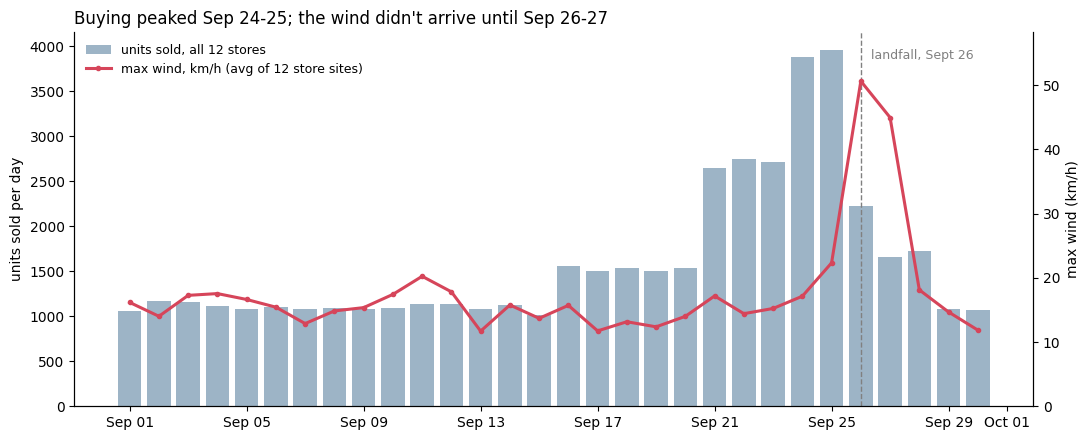

In [ ]:
# chart 1: daily units with wind on a second axis
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(statewide.index, statewide["units"], color="#9db4c6", width=0.8, label="units sold, all 12 stores")
ax.set_ylabel("units sold per day")
ax2 = ax.twinx()
ax2.plot(statewide.index, statewide["max_wind_kmh"], color="#d6455a", lw=2.2, marker="o", ms=3,
         label="max wind, km/h (avg of 12 store sites)")
ax2.set_ylabel("max wind (km/h)")
ax2.set_ylim(0, statewide["max_wind_kmh"].max() * 1.15)
ax.axvline(LANDFALL, ls="--", color="gray", lw=1)
ax.annotate("landfall, Sept 26", xy=(LANDFALL + pd.Timedelta(hours=8), ax.get_ylim()[1] * 0.93), fontsize=9, color="gray")
top_sales = sorted(statewide["units"].nlargest(2).index)
top_wind = sorted(statewide["max_wind_kmh"].nlargest(2).index)
ax.set_title(f"Buying peaked {top_sales[0]:%b %d}-{top_sales[1]:%d}; the wind didn't arrive until "
             f"{top_wind[0]:%b %d}-{top_wind[1]:%d}", loc="left", fontsize=12)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
handles = ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax.legend(handles, [h.get_label() for h in handles], frameon=False, fontsize=9, loc="upper left")
for axis in (ax, ax2):
    axis.spines["top"].set_visible(False)
plt.tight_layout()
plt.show()

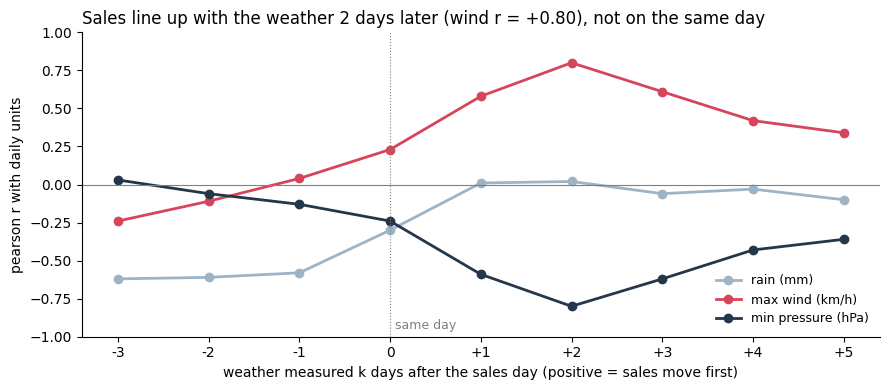

n per lag: {-3: 27, -2: 28, -1: 29, 0: 30, 1: 29, 2: 28, 3: 27, 4: 26, 5: 25}


In [ ]:
# chart 2: correlation at each lag
fig, ax = plt.subplots(figsize=(9, 4))
colors = {"max_wind_kmh": "#d6455a", "min_pressure_hpa": "#24364a", "precipitation_mm": "#9db4c6"}
for column in WEATHER_COLUMNS:
    label = WEATHER_LABELS[column]
    ax.plot(lag_table.index, lag_table[label], marker="o", color=colors[column], lw=2, label=label)
ax.axhline(0, color="gray", lw=0.8)
ax.axvline(0, color="gray", lw=0.8, ls=":")
ax.annotate("same day", xy=(0.05, -0.95), fontsize=9, color="gray")
ax.set_xticks(list(LAGS))
ax.set_xticklabels([f"{k:+d}" if k else "0" for k in LAGS])
ax.set_xlabel("weather measured k days after the sales day (positive = sales move first)")
ax.set_ylabel("pearson r with daily units")
ax.set_ylim(-1, 1)
ax.set_title(f"Sales line up with the weather {best_lag} days later (wind r = "
             f"{lag_table.loc[best_lag, WEATHER_LABELS['max_wind_kmh']]:+.2f}), not on the same day",
             loc="left", fontsize=12)
ax.legend(frameon=False, fontsize=9, loc="lower right")
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()
print("n per lag:", lag_table["n_days"].to_dict())

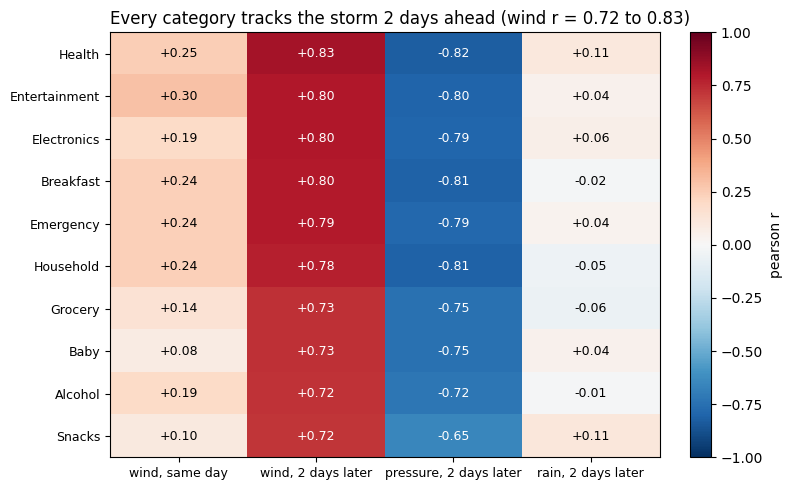

n = 30 days same day, 28 days lagged


In [ ]:
# chart 3: every category, same day vs the best lag
measures = {
    "wind, same day": statewide["max_wind_kmh"],
    f"wind, {best_lag} days later": statewide["max_wind_kmh"].shift(-best_lag),
    f"pressure, {best_lag} days later": statewide["min_pressure_hpa"].shift(-best_lag),
    f"rain, {best_lag} days later": statewide["precipitation_mm"].shift(-best_lag),
}
category_corr = pd.DataFrame({
    name: {category: category_daily[category].corr(weather) for category in category_daily.columns}
    for name, weather in measures.items()
}).sort_values(f"wind, {best_lag} days later", ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
image = ax.imshow(category_corr.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(category_corr.columns)))
ax.set_xticklabels(category_corr.columns, fontsize=9)
ax.set_yticks(range(len(category_corr.index)))
ax.set_yticklabels(category_corr.index, fontsize=9)
for (i, j), value in np.ndenumerate(category_corr.values):
    ax.text(j, i, f"{value:+.2f}", ha="center", va="center", fontsize=9,
            color="white" if abs(value) > 0.6 else "black")
wind_lag = category_corr[f"wind, {best_lag} days later"]
ax.set_title(f"Every category tracks the storm {best_lag} days ahead "
             f"(wind r = {wind_lag.min():.2f} to {wind_lag.max():.2f})", loc="left", fontsize=12)
fig.colorbar(image, ax=ax, fraction=0.04, label="pearson r")
plt.tight_layout()
plt.show()
print(f"n = {len(statewide)} days same day, {len(statewide) - best_lag} days lagged")

**Q3 answer, with its caveat:** Same day, the weather barely moves sales. Across the 30 days of September, daily units correlate weakly with that day's weather: wind r = +0.23, pressure r = −0.24, rain r = −0.30. On landfall day itself (Sept 26), with the strongest wind and lowest pressure of the month, sales were already falling.

Two days ahead, the relationship is strong: there is a detectable lag of about two days. Sales line up with the weather 2 days later: wind r = +0.80 and pressure r = −0.80 (n = 28 days). The store-by-store check agrees. Every one of the 12 stores sold the most 1–3 days before its own lowest pressure (median 2 days), and 11 of 12 sold the most 1–3 days before their own windiest day. The exception is Pensacola, whose windiest day was Sept 12, during Hurricane Francine's landfall in Louisiana, and its sales did not surge then. That supports the reading that people buy on the forecast, not on the weather outside. All 10 categories follow the same two-day lead (wind r = 0.72 to 0.83), so this is the whole basket moving with one storm, not some categories being more weather-sensitive than others.

Rain is not a useful indicator. It is near zero at every positive lag. The negative correlation with rain in the days before a sale (r ≈ −0.6) is timing, not cause: the week before Helene happened to be dry (under 1 mm a day from Sept 19–24) while the surge was building.

Caveats:

This is one month and one storm. The rank (spearman) correlations at the 2-day lag are much weaker (wind +0.25, pressure −0.38), which means the strong pearson r comes from the storm days themselves, not from a steady relationship on ordinary days.
So the 0.80 describes Helene's timing, not a model to forecast sales from weather.
Statewide weather is an average of 12 store sites. The store-day version (n = 336, not independent because every store saw the same storm) gives the same picture: wind r = +0.69, pressure r = −0.72 at the 2-day lag.
For Walmart: don't wait for the weather to turn. The buying happens on the forecast, about two days before the worst conditions, so stock has to be on the shelves before then.

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):**  Have not begun to work on this question. Holden will be in charge of this question

**Q5 (signal or artifact):** _..._

### Self-check

In [ ]:
progress = {
    'q1_multiple': 1.89,            # TODO: a number
    'q1_baseline_window': 'September 1-September 18',   # TODO: stated explicitly
    'q2_canonical_products': 20,  # TODO: a number
    'q3_join_rows_preserved': True, # TODO: True/False
    'q3_days_in_correlation': 30 , # TODO: a number
    'charts_with_message_titles': 5 ,  # TODO: how many
    'notebook_runs_clean': False,   # TODO: True after Restart and Run All
    'repo_pushed': False,           # TODO
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

PASS - q1_multiple = 1.89
PASS - q1_baseline_window = September 1-September 18
PASS - q2_canonical_products = 20
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 30
PASS - charts_with_message_titles = 5
FAIL - notebook_runs_clean = False
FAIL - repo_pushed = False

ready for presentations: False


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

One finding that surprised our team was that sales seemed to peak before the worst weather instead of during it. At all 12 stores, sales peaked 1–3 days before the lowest pressure, and at 11 of the 12 stores, sales peaked 1–3 days before the windiest day. We checked this by looking at the individual store dates instead of only the overall graph, and we also checked the lag correlations. The strongest relationship for wind and pressure was at a +2 day lag, which made us more confident that the pattern was not just from a mistake in the data or graph.

**b)** One number you reported that you are least confident in, and why.

The number we are least confident in is the +0.80 correlation between wind and sales at a +2 day lag. The correlation is pretty strong, but it is based on only 28 days of statewide data, so there are not that many observations. Also, the data covers the period around one hurricane, so we can't be sure the same relationship would happen with other storms or in a longer time period. We think the pattern is interesting, but we would want more data before being very confident in the exact correlation.

_your answer here_